# VIC02 — rockfish model, fine-tuned version

Built on `vic02_pipeline_test.ipynb` (the baseline). It reuses the baseline's detector (Community Fish Detector, MBARI-315k fallback), CLAHE-for-detection, crop padding, BioCLIP 2.5 loading and taxonomic prompt format.

**What is new**

- Runs on real ONC frames from `data/labels/merged_manifest.csv` (`final_label`, `split_final`, `sample_weight`; camera-day splits), streamed straight from the S3 zips without downloading them (same access as `WhatsThatCritter_starter.ipynb` — run its Step 1 once to save the key). The baseline was only scored on 4 iNaturalist photos.
- **Target = rockfish (*Sebastes*) present / absent.** The data has no verified species labels, so species is shown only as an *unvalidated plausible species* hint.
- Compares four methods on the same frames: baseline zero-shot (15 taxa), zero-shot with ONC taxa + background prompts, **frozen BioCLIP + linear probe (MIL)**, and **fine-tuning the last ViT blocks** (optional).
- Thresholds are learned on val (not placeholders). Test results come with camera-day bootstrap CIs, plus a leave-one-camera-out check.
- Output records keep the baseline's format so the website can swap this in.

Run top to bottom **on the hackathon hub**. Step 1 (embeddings) is the slow part and is cached in `vic02_work/finetune_run/`; final outputs are also uploaded to `TEAM_DIR/vic02_finetune_run/`.

In [1]:
!nvidia-smi

Sat Oct 17 23:20:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:1E.0 Off |                    0 |
| N/A   33C    P0             25W /   70W |    6159MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Same approach as the baseline: pin numpy/torch/torchvision to what the image already has.
import subprocess, sys
pins = [l for l in subprocess.check_output([sys.executable, "-m", "pip", "freeze"]).decode().splitlines()
        if l.split("==")[0].lower() in ("numpy", "torch", "torchvision")]
open("vic02_constraints.txt", "w").write("\n".join(pins) + "\n")
print(pins)
%pip install -q -c vic02_constraints.txt open_clip_torch ultralytics huggingface_hub s3fs boto3 scikit-learn pandas matplotlib pillow requests

['numpy==2.5.4']
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, io, json, time, random, zipfile, contextlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# CUDA on the hub; MPS/CPU also work for everything except fine-tuning.
if torch.cuda.is_available():
    DEVICE = "cuda:0"; torch.backends.cudnn.benchmark = True
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
YOLO_DEVICE = 0 if DEVICE.startswith("cuda") else DEVICE

def autocast():
    return torch.autocast("cuda") if DEVICE.startswith("cuda") else contextlib.nullcontext()

@contextlib.contextmanager
def trusted_torch_load():
    """weights_only=False ONLY while loading the detector weights (the baseline patched torch.load globally)."""
    orig = torch.load
    torch.load = lambda *a, **k: orig(*a, **{**k, "weights_only": False})
    try:
        yield
    finally:
        torch.load = orig

def log(msg):
    print(time.strftime("%H:%M:%S"), msg, flush=True)

print("device:", DEVICE, "| torch", torch.__version__)

device: cuda:0 | torch 2.9.1


In [8]:
# ---------------- config ----------------
import configparser, boto3, s3fs

# S3 access, same as WhatsThatCritter_starter.ipynb Step 2. The key stays in ~/.aws/credentials - never put it here.
DATA_FOLDER = "critter"       # your team's data folder - no need to change this

PROFILE = "hack-team"            # use the key you saved in Step 1 (the hub's own AWS login can't see this data)
_cred = configparser.ConfigParser(); _cred.read(os.path.expanduser("~/.aws/credentials"))
if PROFILE not in _cred:
    print("Run Step 1 of WhatsThatCritter_starter.ipynb first to save your key")
    raise SystemExit(f"AWS profile '{PROFILE}' not found in ~/.aws/credentials")
BUCKET  = "ocean-hackathon-2026"
fs = s3fs.S3FileSystem(profile=PROFILE)

# Ask AWS which team this key belongs to, so you never have to type your team name
who = boto3.Session(profile_name=PROFILE).client("sts").get_caller_identity()["Arn"]
TEAM = who.split("/")[-1]                      # e.g. "team-sound"
TEAM_DIR = f"{BUCKET}/teams/{TEAM}"            # your team's workspace (you can save files here)
DATA_DIR = f"{BUCKET}/data/{DATA_FOLDER}"      # your raw data (read-only)
print("Connected as:", TEAM, "| data:", "s3://" + DATA_DIR, "| outputs:", "s3://" + TEAM_DIR)

S3_BLOCK_SIZE = 2 * 2**20   # bytes per S3 range request when reading zip members; tune with the timing cell

WORK = Path("vic02_work"); (WORK / "weights").mkdir(parents=True, exist_ok=True)
RUN = WORK / "finetune_run"; RUN.mkdir(exist_ok=True)
CROPS_DIR = RUN / "crops"; CROPS_DIR.mkdir(exist_ok=True)

MANIFEST = "data/labels/merged_manifest.csv"   # team-critters repo: manifest.csv + human-reviewed clean set
LABEL_COL = "final_label"
SPLIT_COL = "split_final"
VERIFIED_CSV = None         # optional CSV image_file,label from human checking; overrides final_label

# detector / crops: same values as the baseline
DETECTOR_CHAIN = ["cfd", "mbari_315k"]   # SAM3 dropped: gated, and skipped in the baseline run anyway
CFD_IMGSZ = 1024
DET_CONF = 0.25
MAX_DETS = 10
CROP_PAD = 0.15
USE_CLAHE = True            # detection only; classification uses crops of the original image (as in baseline)
MIN_CROP = 16
BIOCLIP_MODELS = ["hf-hub:imageomics/bioclip-2.5-vith14", "hf-hub:imageomics/bioclip-2"]

# decision targets; the thresholds themselves are learned on val
TARGET_PRECISION = 0.90     # "Identified" must reach this precision on val
REVIEW_RECALL = 0.90        # "Identified" + "Needs review" must keep this share of val positives
SPECIES_MIN = 0.60          # minimum prob to show a plausible species hint

# optional fine-tuning (CUDA only). If you hit OOM: FT_BATCH = 4, or FT_BLOCKS = 1.
RUN_FINETUNE = True
FT_BLOCKS = 2
FT_EPOCHS = 8
FT_LR = 1e-5
HEAD_LR = 1e-3
FT_BATCH = 8

Connected as: team-critter | data: s3://ocean-hackathon-2026/data/critter | outputs: s3://ocean-hackathon-2026/teams/team-critter


## Data: ONC frames from `data/labels/merged_manifest.csv`, streamed from the S3 zips

In [9]:
df = pd.read_csv(MANIFEST)
df["tier"] = df["tier"].fillna("")
df["manifest_label"], df["manifest_split"] = df["label"], df["split"]   # original manifest.csv values, reference only
SPLITS = ["train", "val", "test"]
if VERIFIED_CSV:
    ov = pd.read_csv(VERIFIED_CSV).set_index("image_file")["label"]
    bad = sorted(set(ov) - {"positive", "negative", "excluded"})
    assert not bad, f"VERIFIED_CSV has unknown labels: {bad}"
    hit = df.image_file.isin(ov.index)
    df.loc[hit, LABEL_COL] = df.loc[hit, "image_file"].map(ov)
    df.loc[hit, "sample_weight"] = 1.0                       # human-verified -> full weight
    ex = hit & (df[LABEL_COL] == "excluded")
    df.loc[ex, "sample_weight"] = 0.0
    df.loc[ex, SPLIT_COL] = "excluded"
    # a frame overridden from excluded to positive/negative takes its camera_day's split (if there is exactly one)
    day_split = df[df[SPLIT_COL].isin(SPLITS)].groupby("camera_day")[SPLIT_COL].agg(set)
    need = hit & ~ex & ~df[SPLIT_COL].isin(SPLITS)
    for i in df.index[need]:
        s = day_split.get(df.at[i, "camera_day"], set())
        df.at[i, SPLIT_COL] = next(iter(s)) if len(s) == 1 else "unassigned"
    print("human overrides applied:", int(hit.sum()), "| set to excluded:", int(ex.sum()),
          "| unassigned after override:", int((need & (df[SPLIT_COL] == "unassigned")).sum()))

df["label"], df["split"] = df[LABEL_COL], df[SPLIT_COL]   # later cells use these names
df["tier_group"] = df["tier"].replace("", "not in clean set")
df["y"] = df.label.map({"positive": 1, "negative": 0}).fillna(-1).astype(int)
df.loc[~df.split.isin(SPLITS), "y"] = -1                  # 'excluded' / 'unassigned' never train or evaluate
assert (df.loc[df.y >= 0, "sample_weight"] > 0).all(), "a train/val/test frame has sample_weight 0"
display(pd.crosstab(df.split, df.label))

# open each zip ONCE, remotely: only the bytes that are needed are fetched (no full download)
ZIPS = {}
for zp in df.zip_path.unique():
    ZIPS[zp] = zipfile.ZipFile(fs.open(zp, "rb", block_size=S3_BLOCK_SIZE))   # zip_path already starts with the bucket
    log(f"opened {zp}")
NAMES = {zp: set(z.namelist()) for zp, z in ZIPS.items()}
missing = [m for zp, m in zip(df.zip_path, df.image_member) if m not in NAMES[zp]]
assert not missing, f"{len(missing)} image_member(s) not in their zip, first 5: {missing[:5]}"

def load_frame(row):
    return np.array(Image.open(io.BytesIO(ZIPS[row.zip_path].read(row.image_member))).convert("RGB"))


label,excluded,negative,positive
split,,,
excluded,78,0,0
test,0,51,12
train,0,233,58
val,0,50,12


23:28:19 opened ocean-hackathon-2026/data/critter/china_creek_images.zip
23:28:19 opened ocean-hackathon-2026/data/critter/hartley_bay_images.zip
23:28:20 opened ocean-hackathon-2026/data/critter/campbell_river_images.zip


In [10]:
# S3 streaming speed: open one zip and read 3 images. If slow, change S3_BLOCK_SIZE in the config cell.
zp = df.zip_path.iloc[0]
t0 = time.time()
zt = zipfile.ZipFile(fs.open(zp, "rb", block_size=S3_BLOCK_SIZE))
t_open = time.time() - t0
times = []
for m in df[df.zip_path == zp].image_member.head(3):
    t0 = time.time(); n = len(zt.read(m)); times.append(time.time() - t0)
    print(f"  {m.split('/')[-1]}: {times[-1]:.2f} s ({n / 1e3:.0f} kB)")
zt.close()
print(f"block_size {S3_BLOCK_SIZE / 2**20:.1f} MiB | open zip {t_open:.2f} s | {np.mean(times):.2f} s per image "
      f"(~{np.mean(times) * len(df) / 60:.1f} min to read all {len(df)} frames)")


  AXISCAMACCC8ED95D9B_20221122T220007.000Z_t0234.00.jpg: 0.15 s (242 kB)
  AXISCAMACCC8ED95D9B_20220115T170006.000Z_t0004.00.jpg: 0.20 s (233 kB)
  AXISCAMACCC8ED95D9B_20220628T200008.000Z_t0036.00.jpg: 0.21 s (279 kB)
block_size 2.0 MiB | open zip 0.10 s | 0.19 s per image (~1.5 min to read all 494 frames)


In [11]:
# Optional, read-only: show the CSVs packed inside each zip (for later EOV / depth work).
# Reads only the .csv members, never the whole zip.
PEEK_ZIP_CSVS = True
if PEEK_ZIP_CSVS:
    for zp, z in ZIPS.items():
        csvs = [m for m in z.namelist() if m.lower().endswith(".csv")]
        print(f"\n##### {zp}: {len(csvs)} csv member(s)")
        for m in csvs:
            t = pd.read_csv(io.BytesIO(z.read(m)))
            print(f"--- {m}: {t.shape[0]} rows x {t.shape[1]} cols\ncolumns: {list(t.columns)}")
            display(t.head(3))



##### ocean-hackathon-2026/data/critter/china_creek_images.zip: 3 csv member(s)
--- china_creek_images/imaged_annotations.csv: 1331 rows x 56 cols
columns: ['annotation_id', 'annotation_source', 'annotation_comment', 'annotation_start_utc', 'annotation_end_utc', 'annotation_duration_seconds', 'camera_mode', 'dive_id', 'dive_name', 'cruise_name', 'stationary_search_tree_node_id', 'stationary_location_name', 'stationary_location_path', 'resource_type_id', 'resource_type_name', 'device_id', 'video_resource_id', 'video_resource_type_id', 'creator_user_id', 'creator_first_name', 'creator_last_name', 'creator_email', 'modifier_user_id', 'modifier_first_name', 'modifier_last_name', 'modifier_email', 'created_date_utc', 'modified_date_utc', 'lat', 'lon', 'depth_m', 'heading_deg', 'to_be_reviewed', 'num_positive_reviews', 'num_total_reviews', 'taxonomy_index', 'taxonomy_code', 'taxonomy_id', 'taxon_id', 'taxon_display_text', 'taxon_scientific_name', 'worms_aphia_id', 'taxon_url', 'taxon_attrib

,annotation_id,annotation_source,annotation_comment,annotation_start_utc,annotation_end_utc,annotation_duration_seconds,camera_mode,dive_id,dive_name,cruise_name,...,video_resolution_code,video_device_code,clip_offset_seconds,clip_duration_seconds,clip_relative_path,clip_row_start_offset_seconds,archive_clip_start_utc,video_local_path,video_downloaded,contextual_link
0,18217600,DMAS,NaN,2022-03-21T09:00:10.000Z,2022-03-21T09:00:10.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,AXISCAMACCC8ED95D9B,NaN,298.0,NaN,NaN,2022-03-21T09:00:07.000Z,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...
1,18217500,DMAS,NaN,2022-03-21T09:00:10.000Z,2022-03-21T09:00:10.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,AXISCAMACCC8ED95D9B,NaN,298.0,NaN,NaN,2022-03-21T09:00:07.000Z,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...
2,18217400,DMAS,NaN,2022-03-21T09:00:10.000Z,2022-03-21T09:00:10.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,AXISCAMACCC8ED95D9B,NaN,298.0,NaN,NaN,2022-03-21T09:00:07.000Z,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...


--- china_creek_images/images_index.csv: 918 rows x 17 cols
columns: ['image_file', 'frame_utc', 'archive_filename', 'offset_seconds', 'taxa', 'worms_aphia_ids', 'groups', 'annotation_ids', 'annotation_count', 'camera_mode', 'dive_name', 'location', 'lat', 'lon', 'depth_m', 'creators', 'seatube_link']


,image_file,frame_utc,archive_filename,offset_seconds,taxa,worms_aphia_ids,groups,annotation_ids,annotation_count,camera_mode,dive_name,location,lat,lon,depth_m,creators,seatube_link
0,AXISCAMACCC8ED95D9B_20210930T190006.000Z_t0012...,2021-09-30T19:00:18.000Z,AXISCAMACCC8ED95D9B_20210930T190006.000Z.mp4,12.0,Pleuronectiformes,10331,fish,18162200,2,stationary,NaN,China Creek Underwater Network,49.153733,-124.802283,NaN,Sofia Jimenez Gonzalez,https://data.oceannetworks.ca/SeaTube?resource...
1,AXISCAMACCC8ED95D9B_20211001T010005.000Z_t0124...,2021-10-01T01:02:09.000Z,AXISCAMACCC8ED95D9B_20211001T010005.000Z.mp4,124.0,Pandalus platyceros,423632,crustaceans; shrimp,18162300,2,stationary,NaN,China Creek Underwater Network,49.153733,-124.802283,NaN,Sofia Jimenez Gonzalez,https://data.oceannetworks.ca/SeaTube?resource...
2,AXISCAMACCC8ED95D9B_20211002T080009.000Z_t0117...,2021-10-02T08:02:06.000Z,AXISCAMACCC8ED95D9B_20211002T080009.000Z.mp4,117.0,Agonidae,125588,fish,18162400,2,stationary,NaN,China Creek Underwater Network,49.153733,-124.802283,NaN,Sofia Jimenez Gonzalez,https://data.oceannetworks.ca/SeaTube?resource...


--- china_creek_images/unmapped_annotations.csv: 28 rows x 56 cols
columns: ['annotation_id', 'annotation_source', 'annotation_comment', 'annotation_start_utc', 'annotation_end_utc', 'annotation_duration_seconds', 'camera_mode', 'dive_id', 'dive_name', 'cruise_name', 'stationary_search_tree_node_id', 'stationary_location_name', 'stationary_location_path', 'resource_type_id', 'resource_type_name', 'device_id', 'video_resource_id', 'video_resource_type_id', 'creator_user_id', 'creator_first_name', 'creator_last_name', 'creator_email', 'modifier_user_id', 'modifier_first_name', 'modifier_last_name', 'modifier_email', 'created_date_utc', 'modified_date_utc', 'lat', 'lon', 'depth_m', 'heading_deg', 'to_be_reviewed', 'num_positive_reviews', 'num_total_reviews', 'taxonomy_index', 'taxonomy_code', 'taxonomy_id', 'taxon_id', 'taxon_display_text', 'taxon_scientific_name', 'worms_aphia_id', 'taxon_url', 'taxon_attributes_json', 'archive_filename', 'video_mapping_status', 'video_resolution_code', 

...

,annotation_id,annotation_source,annotation_comment,annotation_start_utc,annotation_end_utc,annotation_duration_seconds,camera_mode,dive_id,dive_name,cruise_name,...,video_resolution_code,video_device_code,clip_offset_seconds,clip_duration_seconds,clip_relative_path,clip_row_start_offset_seconds,archive_clip_start_utc,video_local_path,video_downloaded,contextual_link
0,18377400,DMAS,NaN,2019-09-08T21:00:10.000Z,2019-09-08T21:00:10.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,AXISCAMACCC8E891288,NaN,301.0,NaN,NaN,2019-09-08T21:00:08.000Z,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...
1,18377600,DMAS,NaN,2019-09-08T21:00:31.000Z,2019-09-08T21:00:31.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,AXISCAMACCC8E891288,NaN,301.0,NaN,NaN,2019-09-08T21:00:08.000Z,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...
2,18377500,DMAS,NaN,2019-09-08T21:00:31.000Z,2019-09-08T21:00:31.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,AXISCAMACCC8E891288,NaN,301.0,NaN,NaN,2019-09-08T21:00:08.000Z,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...


--- campbell_river_images/images_index.csv: 1177 rows x 17 cols
columns: ['image_file', 'frame_utc', 'archive_filename', 'offset_seconds', 'taxa', 'worms_aphia_ids', 'groups', 'annotation_ids', 'annotation_count', 'camera_mode', 'dive_name', 'location', 'lat', 'lon', 'depth_m', 'creators', 'seatube_link']


,image_file,frame_utc,archive_filename,offset_seconds,taxa,worms_aphia_ids,groups,annotation_ids,annotation_count,camera_mode,dive_name,location,lat,lon,depth_m,creators,seatube_link
0,AXISCAMACCC8E891288_20190104T160007.000Z_t0145...,2019-01-04T16:02:32.000Z,AXISCAMACCC8E891288_20190104T160007.000Z.mp4,145.0,Hexagrammos decagrammus,240732,fish,18296800,1,stationary,NaN,Campbell River Underwater Network,50.020767,-125.23535,NaN,Mauricio Carrasquilla,https://data.oceannetworks.ca/SeaTube?resource...
1,AXISCAMACCC8E891288_20190104T200009.000Z_t0011...,2019-01-04T20:00:20.000Z,AXISCAMACCC8E891288_20190104T200009.000Z.mp4,11.0,Hexagrammos decagrammus,240732,fish,18296700,1,stationary,NaN,Campbell River Underwater Network,50.020767,-125.23535,NaN,Mauricio Carrasquilla,https://data.oceannetworks.ca/SeaTube?resource...
2,AXISCAMACCC8E891288_20190107T010008.000Z_t0130...,2019-01-07T01:02:18.000Z,AXISCAMACCC8E891288_20190107T010008.000Z.mp4,130.0,Hexagrammos decagrammus,240732,fish,18296900,1,stationary,NaN,Campbell River Underwater Network,50.020767,-125.23535,NaN,Mauricio Carrasquilla,https://data.oceannetworks.ca/SeaTube?resource...


--- campbell_river_images/unmapped_annotations.csv: 10 rows x 56 cols
columns: ['annotation_id', 'annotation_source', 'annotation_comment', 'annotation_start_utc', 'annotation_end_utc', 'annotation_duration_seconds', 'camera_mode', 'dive_id', 'dive_name', 'cruise_name', 'stationary_search_tree_node_id', 'stationary_location_name', 'stationary_location_path', 'resource_type_id', 'resource_type_name', 'device_id', 'video_resource_id', 'video_resource_type_id', 'creator_user_id', 'creator_first_name', 'creator_last_name', 'creator_email', 'modifier_user_id', 'modifier_first_name', 'modifier_last_name', 'modifier_email', 'created_date_utc', 'modified_date_utc', 'lat', 'lon', 'depth_m', 'heading_deg', 'to_be_reviewed', 'num_positive_reviews', 'num_total_reviews', 'taxonomy_index', 'taxonomy_code', 'taxonomy_id', 'taxon_id', 'taxon_display_text', 'taxon_scientific_name', 'worms_aphia_id', 'taxon_url', 'taxon_attributes_json', 'archive_filename', 'video_mapping_status', 'video_resolution_code

,annotation_id,annotation_source,annotation_comment,annotation_start_utc,annotation_end_utc,annotation_duration_seconds,camera_mode,dive_id,dive_name,cruise_name,...,video_resolution_code,video_device_code,clip_offset_seconds,clip_duration_seconds,clip_relative_path,clip_row_start_offset_seconds,archive_clip_start_utc,video_local_path,video_downloaded,contextual_link
0,18387300,DMAS,NaN,2019-10-10T16:00:10.000Z,2019-10-10T16:00:10.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...
1,18384100,DMAS,NaN,2019-10-09T14:09:45.000Z,2019-10-09T14:09:45.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...
2,18375200,DMAS,NaN,2019-09-07T23:00:03.000Z,2019-09-07T23:00:03.000Z,0.0,stationary,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://data.oceannetworks.ca/SeaTube?resource...


## Detector (from the baseline)

In [12]:
def _download(url, dest):
    import requests
    tmp = Path(str(dest) + ".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    tmp.rename(dest)

def load_cfd():
    url = ("https://github.com/WildHackers/community-fish-detector/"
           "releases/download/cfd-1.00-yolov12x/cfd-yolov12x-1.00.pt")
    dest = WORK / "weights" / "cfd-yolov12x-1.00.pt"
    if not dest.exists():
        log("CFD: downloading weights from GitHub ...")
        _download(url, dest)
    from ultralytics import YOLO
    with trusted_torch_load():
        m = YOLO(str(dest))

    def detect(img_rgb):
        r = m.predict(Image.fromarray(img_rgb), conf=DET_CONF, imgsz=CFD_IMGSZ, device=YOLO_DEVICE, verbose=False)[0]
        return [(float(x1), float(y1), float(x2), float(y2), float(c), "fish")
                for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())]
    return detect

def load_mbari_315k():
    from huggingface_hub import list_repo_files, hf_hub_download
    from ultralytics import YOLO
    repo = "FathomNet/MBARI-315k-yolov8"
    pt = sorted(f for f in list_repo_files(repo) if f.endswith(".pt"))[0]
    with trusted_torch_load():
        m = YOLO(hf_hub_download(repo, pt))

    def detect(img_rgb):
        r = m.predict(Image.fromarray(img_rgb), conf=DET_CONF, device=YOLO_DEVICE, verbose=False)[0]
        return [(float(x1), float(y1), float(x2), float(y2), float(cf), r.names[int(c)])
                for (x1, y1, x2, y2), cf, c in zip(r.boxes.xyxy.cpu().numpy(),
                                                   r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy())]
    return detect

LOADERS = {"cfd": load_cfd, "mbari_315k": load_mbari_315k}
DETECTORS = {}
for name in DETECTOR_CHAIN:
    try:
        DETECTORS[name] = LOADERS[name](); log(f"{name}: ready")
    except Exception as ex:
        log(f"{name}: skipped ({type(ex).__name__}: {ex})")
assert DETECTORS, "No detector could be loaded"

def detect(img_rgb):
    for name, fn in DETECTORS.items():
        dets = fn(img_rgb)
        if dets:
            return [d + (name,) for d in dets]
    return []

def clahe(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def crop(img_rgb, box):
    h, w = img_rgb.shape[:2]
    x1, y1, x2, y2 = box[:4]
    px, py = (x2 - x1) * CROP_PAD, (y2 - y1) * CROP_PAD
    x1, y1 = max(0, int(x1 - px)), max(0, int(y1 - py))
    x2, y2 = min(w, int(x2 + px)), min(h, int(y2 + py))
    return Image.fromarray(img_rgb[y1:y2, x1:x2])

23:28:32 CFD: downloading weights from GitHub ...
23:28:35 cfd: ready
23:28:36 mbari_315k: ready


## BioCLIP 2.5 and prompts

`CANDIDATES` should be the same 15 taxa as baseline cell 5. **If your lineage strings differ, paste the baseline's list here** so the "baseline zero-shot" row is an exact reproduction. `EXTRA_CANDIDATES` adds taxa that actually appear in ONC's `onc_taxa`, and `BACKGROUND` adds the "no animal" prompts from `critter_pipeline_v2`.

In [13]:
import open_clip

# (kingdom, phylum, class, order, family, genus, epithet, common name) — baseline format
_SEB = ("Animalia", "Chordata", "Actinopterygii", "Scorpaeniformes", "Sebastidae")
CANDIDATES = [
    _SEB + ("Sebastes", "ruberrimus", "yelloweye rockfish"),
    _SEB + ("Sebastes", "maliger", "quillback rockfish"),
    _SEB + ("Sebastes", "caurinus", "copper rockfish"),
    _SEB + ("Sebastes", "melanops", "black rockfish"),
    _SEB + ("Sebastes", "nebulosus", "China rockfish"),
    _SEB + ("Sebastes", "pinniger", "canary rockfish"),
    _SEB + ("Sebastolobus", "alascanus", "shortspine thornyhead"),
    _SEB + ("Sebastolobus", "altivelis", "longspine thornyhead"),
    ("Animalia", "Chordata", "Actinopterygii", "Scorpaeniformes", "Hexagrammidae", "Ophiodon", "elongatus", "lingcod"),
    ("Animalia", "Chordata", "Actinopterygii", "Scorpaeniformes", "Hexagrammidae", "Hexagrammos", "decagrammus", "kelp greenling"),
    ("Animalia", "Chordata", "Actinopterygii", "Scorpaeniformes", "Cottidae", "Scorpaenichthys", "marmoratus", "cabezon"),
    ("Animalia", "Arthropoda", "Malacostraca", "Decapoda", "Cancridae", "Metacarcinus", "magister", "Dungeness crab"),
    ("Animalia", "Arthropoda", "Malacostraca", "Decapoda", "Cancridae", "Cancer", "productus", "red rock crab"),
    ("Animalia", "Echinodermata", "Asteroidea", "Forcipulatida", "Asteriidae", "Pisaster", "ochraceus", "ochre sea star"),
    ("Animalia", "Echinodermata", "Holothuroidea", "Synallactida", "Stichopodidae", "Apostichopus", "californicus", "California sea cucumber"),
]
EXTRA_CANDIDATES = [   # seen in onc_taxa
    ("Animalia", "Chordata", "Actinopterygii", "Pleuronectiformes", "Pleuronectidae", "Lyopsetta", "exilis", "slender sole"),
    ("Animalia", "Chordata", "Chondrichthyes", "Squaliformes", "Squalidae", "Squalus", "acanthias", "spiny dogfish"),
    ("Animalia", "Chordata", "Actinopterygii", "Clupeiformes", "Clupeidae", "Clupea", "pallasii", "Pacific herring"),
    ("Animalia", "Chordata", "Chondrichthyes", "Chimaeriformes", "Chimaeridae", "Hydrolagus", "colliei", "spotted ratfish"),
    ("Animalia", "Chordata", "Actinopterygii", "Gadiformes", "Gadidae", "Gadus", "macrocephalus", "Pacific cod"),
    ("Animalia", "Chordata", "Actinopterygii", "Perciformes", "Agonidae", "Podothecus", "accipenserinus", "sturgeon poacher"),
    ("Animalia", "Arthropoda", "Malacostraca", "Decapoda", "Munididae", "Munida", "quadrispina", "squat lobster"),
    ("Animalia", "Arthropoda", "Malacostraca", "Decapoda", "Pandalidae", "Pandalus", "platyceros", "spot prawn"),
]
BACKGROUND = ["a rock", "seaweed", "sandy seafloor", "floating particles in dark water"]

def prompt(t):
    return f"a photo of {t[0]} {t[1]} {t[2]} {t[3]} {t[4]} {t[5]} {t[6]} with common name {t[7]}."

clip_model = None
for name in BIOCLIP_MODELS:
    try:
        clip_model, _, clip_pre = open_clip.create_model_and_transforms(name)
        tokenizer = open_clip.get_tokenizer(name); BIOCLIP_NAME = name
        break
    except Exception as ex:
        print(f"[{name} failed to load] {ex}")
assert clip_model is not None
clip_model = clip_model.to(DEVICE).eval()
LOGIT_SCALE = clip_model.logit_scale.exp().item()

def encode_text(prompts):
    with torch.no_grad(), autocast():
        t = clip_model.encode_text(tokenizer(prompts).to(DEVICE))
    return F.normalize(t.float(), dim=-1).cpu().numpy()

ALL_TAXA = CANDIDATES + EXTRA_CANDIDATES
TEXT_BASE = encode_text([prompt(t) for t in CANDIDATES])
TEXT_EXT = encode_text([prompt(t) for t in ALL_TAXA] + [f"a photo of {b}." for b in BACKGROUND])
SEB_BASE = np.array([t[5] == "Sebastes" for t in CANDIDATES])
SEB_EXT = np.array([t[5] == "Sebastes" for t in ALL_TAXA] + [False] * len(BACKGROUND))
SEB_SPECIES = [(f"{t[5]} {t[6]}", t[7]) for t in ALL_TAXA if t[5] == "Sebastes"]
TEXT_SP = TEXT_EXT[np.where(SEB_EXT)[0]]

def embed(pil_images, bs=32):
    """Normalized BioCLIP image embeddings (the baseline's classify() threw these away)."""
    out = []
    for i in range(0, len(pil_images), bs):
        x = torch.stack([clip_pre(im) for im in pil_images[i:i + bs]]).to(DEVICE)
        with torch.no_grad(), autocast():
            f = clip_model.encode_image(x)
        out.append(F.normalize(f.float(), dim=-1).cpu().numpy())
    return np.concatenate(out)

log(f"BioCLIP: {BIOCLIP_NAME} | {len(ALL_TAXA)} taxa + {len(BACKGROUND)} background prompts")

23:28:56 BioCLIP: hf-hub:imageomics/bioclip-2.5-vith14 | 23 taxa + 4 background prompts


## Step 1 — detect, crop and embed every ONC frame (cached)

In [14]:
CACHE = RUN / "embeddings.npz"
if CACHE.exists() and (RUN / "crops.csv").exists():
    crop_emb = np.load(CACHE)["crop_emb"]
    crops_df = pd.read_csv(RUN / "crops.csv")
    log("loaded cached embeddings")
else:
    rows, embs = [], []
    for fi, row in enumerate(tqdm(df.itertuples(), total=len(df))):
        img = load_frame(row)
        dets = sorted(detect(clahe(img) if USE_CLAHE else img), key=lambda d: -d[4])[:MAX_DETS]
        pil = []
        for k, d in enumerate(dets):
            c = crop(img, d)
            if min(c.size) < MIN_CROP:
                continue
            path = CROPS_DIR / f"{Path(row.image_file).stem}_{k}.jpg"
            c.save(path, quality=95)
            pil.append(c)
            rows.append(dict(fi=fi, image_file=row.image_file, crop_path=str(path),
                             x1=d[0], y1=d[1], x2=d[2], y2=d[3], det_conf=d[4], det_label=d[5], det_source=d[6]))
        if pil:
            embs.append(embed(pil))
    crops_df = pd.DataFrame(rows)
    crop_emb = np.concatenate(embs)
    crops_df.to_csv(RUN / "crops.csv", index=False)
    np.savez_compressed(CACHE, crop_emb=crop_emb)

crop_frame = crops_df.fi.values
N = len(df)
has_crop = np.zeros(N, bool); has_crop[crop_frame] = True
log(f"{len(crops_df)} crops from {has_crop.sum()}/{N} frames")
print("detector recall on positive frames:",
      f"{has_crop[df.y == 1].sum()}/{(df.y == 1).sum()}  (missed positives can never be found downstream)")

  0%|          | 0/494 [00:00<?, ?it/s]

23:31:53 404 crops from 322/494 frames
detector recall on positive frames: 73/82  (missed positives can never be found downstream)


## Step 2 — shared helpers and zero-shot scores on the same frames

In [24]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True); e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def frame_max(scores, crop_frame, n):
    out = np.full(n, np.nan)              # NaN = no crop / no score for this frame
    np.fmax.at(out, crop_frame, scores)
    return out

def best_crop(scores, crop_frame, frames):
    best = {}
    for i, f in enumerate(crop_frame):
        if f in frames and not np.isnan(scores[i]) and (f not in best or scores[i] > scores[best[f]]):
            best[f] = i
    return best

def mil_train(crop_emb, crop_frame, y, train_frames, init_scores, C, iters=2, weights=None):
    """No boxes in the labels: positive frame -> its most rockfish-like crop; negative frame -> all crops.
    weights: per-frame sample_weight (training only). Each crop takes its frame's weight; 0-weight frames are skipped."""
    from sklearn.linear_model import LogisticRegression
    w = np.ones(len(y)) if weights is None else np.asarray(weights, dtype=float)
    pos = {f for f in train_frames if y[f] == 1 and w[f] > 0}
    neg = {f for f in train_frames if y[f] == 0 and w[f] > 0}
    neg_idx = [i for i, f in enumerate(crop_frame) if f in neg]
    scores, clf = init_scores, None
    for _ in range(iters):
        pos_idx = list(best_crop(scores, crop_frame, pos).values())
        X = crop_emb[pos_idx + neg_idx]
        t = np.r_[np.ones(len(pos_idx)), np.zeros(len(neg_idx))]
        sw = w[crop_frame[pos_idx + neg_idx]]
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=5000).fit(X, t, sample_weight=sw)
        scores = clf.predict_proba(crop_emb)[:, 1]
    return clf, scores

def ap(s, y):
    from sklearn.metrics import average_precision_score
    return float(average_precision_score(y, np.nan_to_num(s, nan=0.0))) if y.sum() else None

def pick_thresholds(s, y, target_precision, review_recall):
    det = ~np.isnan(s)
    s0 = np.nan_to_num(s, nan=0.0)
    t_high = 1.01   # conservative: precision must hold for every threshold above t_high
    for t in sorted(np.unique(s0[det]), reverse=True):
        if y[s0 >= t].mean() >= target_precision:
            t_high = float(t)
        else:
            break
    pos = np.sort(s[det & (y == 1)])          # only positives the detector actually found
    t_low = float(pos[int(np.floor((1 - review_recall) * len(pos)))]) if len(pos) else 0.5
    return min(t_low, t_high), t_high

def status(score, t_low, t_high):
    if np.isnan(score): return "No detection"
    if score >= t_high: return "Identified"
    if score >= t_low:  return "Needs review"
    return "Not rockfish"

def cluster_ci(fn, groups, n=1000, seed=0):
    rng = np.random.default_rng(seed); ug = np.unique(groups)
    by = {g: np.where(groups == g)[0] for g in ug}; vals = []
    for _ in range(n):
        v = fn(np.concatenate([by[g] for g in rng.choice(ug, len(ug))]))
        if v is not None and not np.isnan(v): vals.append(v)
    return [round(float(x), 3) for x in np.percentile(vals, [2.5, 97.5])] if vals else None

def eval_split(s, y, groups, t_low, t_high):
    det = ~np.isnan(s)
    s0 = np.nan_to_num(s, nan=0.0)
    ident = det & (s0 >= t_high)
    review = det & (s0 >= t_low)               # No detection is never "reviewed"
    prec = lambda i: y[i][ident[i]].mean() if ident[i].sum() else np.nan
    rec = lambda i: ident[i][y[i] == 1].mean() if (y[i] == 1).sum() else np.nan
    return {"n": int(len(y)), "pos": int(y.sum()), "AP": ap(s, y),
            "precision": float(y[ident].mean()) if ident.sum() else None, "precision_95ci": cluster_ci(prec, groups),
            "recall": float(ident[y == 1].mean()) if y.sum() else None, "recall_95ci": cluster_ci(rec, groups),
            "recall_incl_review": float(review[y == 1].mean()) if y.sum() else None,
            "neg_in_review": int((review & ~ident & (y == 0)).sum()),
            "false_identified": int((ident & (y == 0)).sum()),
            "pos_no_detection": int((~det & (y == 1)).sum())}

In [16]:
y = df.y.values; split = df.split.values; groups = df.camera_day.values
W = df.sample_weight.values.astype(float)   # training only; evaluation below is unweighted
idx = {s: np.where((split == s) & (y >= 0))[0] for s in ["train", "val", "test"]}
for s, i in idx.items():
    print(f"{s:5s} frames={len(i):3d}  positives={y[i].sum()}")

# frame score = max over crops of P(genus Sebastes)
zs_base_crop = softmax(LOGIT_SCALE * crop_emb @ TEXT_BASE.T)[:, SEB_BASE].sum(1)   # exactly the baseline label set
zs_ext_crop = softmax(LOGIT_SCALE * crop_emb @ TEXT_EXT.T)[:, SEB_EXT].sum(1)      # + ONC taxa + background
zs_base_f = frame_max(zs_base_crop, crop_frame, N)
zs_ext_f = frame_max(zs_ext_crop, crop_frame, N)
print("val AP  baseline zero-shot:", ap(zs_base_f[idx["val"]], y[idx["val"]]),
      "| extended zero-shot:", ap(zs_ext_f[idx["val"]], y[idx["val"]]))

train frames=291  positives=58
val   frames= 62  positives=12
test  frames= 63  positives=12
val AP  baseline zero-shot: 0.7027885574150431 | extended zero-shot: 0.7426957749538395


## Step 3 — Method A: frozen BioCLIP + linear probe (MIL)

In [18]:
best = None
for C in [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]:
    clf, sc = mil_train(crop_emb, crop_frame, y, idx["train"], zs_ext_crop, C, weights=W)
    a = ap(frame_max(sc, crop_frame, N)[idx["val"]], y[idx["val"]])
    print(f"C={C:<5} val AP={a:.3f}")
    if best is None or a > best[0]:
        best = (a, C, clf, sc)
_, PROBE_C, probe, probe_crop = best
probe_f = frame_max(probe_crop, crop_frame, N)
np.savez(RUN / "probe.npz", coef=probe.coef_[0], intercept=probe.intercept_[0], C=PROBE_C)
log(f"probe: C={PROBE_C}")

C=0.01  val AP=0.791
C=0.03  val AP=0.796
C=0.1   val AP=0.796
C=0.3   val AP=0.790
C=1.0   val AP=0.790
C=3.0   val AP=0.786
23:32:32 probe: C=0.03


## Step 4 — Method B (optional): fine-tune the last ViT blocks

Warm-starts the head from the linear probe, unfreezes only the last `FT_BLOCKS` transformer blocks, uses small learning rates and underwater-style augmentation, and keeps the epoch with the best **val** AP. With ~50 positive training frames this can easily overfit; it is only kept if it beats the probe on val.

In [19]:
ft_frame, ft_crop, FT = None, None, None
vis = clip_model.visual
can_ft = DEVICE.startswith("cuda") and hasattr(vis, "transformer") and hasattr(vis.transformer, "resblocks")
if RUN_FINETUNE and not can_ft:
    print("Skipping fine-tuning (needs CUDA and an open_clip VisionTransformer).")

if RUN_FINETUNE and can_ft:
    from torchvision import transforms as T
    for p in clip_model.parameters():
        p.requires_grad = False
    tune = [p for b in list(vis.transformer.resblocks)[-FT_BLOCKS:] for p in b.parameters()]
    if getattr(vis, "ln_post", None) is not None:
        tune += list(vis.ln_post.parameters())
    if isinstance(getattr(vis, "proj", None), nn.Parameter):
        tune.append(vis.proj)
    for p in tune:
        p.requires_grad = True
    BASE_W = [p.detach().clone() for p in tune]     # frozen weights, to switch back for the probe

    def set_weights(ws):
        with torch.no_grad():
            for p, w in zip(tune, ws): p.copy_(w)

    AUG = T.Compose([T.RandomHorizontalFlip(),
                     T.ColorJitter(0.3, 0.3, 0.2, 0.03),
                     T.RandomApply([T.GaussianBlur(5)], p=0.3),
                     T.RandomAffine(degrees=5, translate=(0.05, 0.05), scale=(0.9, 1.1))])
    head = nn.Linear(crop_emb.shape[1], 1).to(DEVICE)
    with torch.no_grad():
        head.weight.copy_(torch.tensor(probe.coef_)); head.bias.copy_(torch.tensor(probe.intercept_))

    def ft_scores(crop_ids, bs=32):
        out = np.full(len(crop_emb), np.nan)
        with torch.no_grad(), autocast():
            for i in range(0, len(crop_ids), bs):
                ids = crop_ids[i:i + bs]
                x = torch.stack([clip_pre(Image.open(crops_df.crop_path[j]).convert("RGB")) for j in ids]).to(DEVICE)
                f = F.normalize(clip_model.encode_image(x).float(), dim=-1)
                out[ids] = torch.sigmoid(head(f).float()).squeeze(1).cpu().numpy()
        return out

    tr = idx["train"]
    pos_crops = list(best_crop(probe_crop, crop_frame, set(tr[(y[tr] == 1) & (W[tr] > 0)])).values())
    neg_frames = set(tr[(y[tr] == 0) & (W[tr] > 0)])
    neg_crops = [i for i, f in enumerate(crop_frame) if f in neg_frames]
    # (crop index, target, frame sample_weight)
    items = [(i, 1.0, W[crop_frame[i]]) for i in pos_crops] + [(i, 0.0, W[crop_frame[i]]) for i in neg_crops]
    val_crops = np.where(np.isin(crop_frame, idx["val"]))[0]
    pos_w = torch.tensor([len(neg_crops) / max(1, len(pos_crops))], device=DEVICE)
    opt = torch.optim.AdamW([{"params": tune, "lr": FT_LR}, {"params": head.parameters(), "lr": HEAD_LR}],
                            weight_decay=0.05)
    scaler = torch.cuda.amp.GradScaler()
    print(f"fine-tuning on {len(pos_crops)} positive / {len(neg_crops)} negative crops")

    best_ap, best_state = ap(probe_f[idx["val"]], y[idx["val"]]), None   # must beat the probe
    for ep in range(FT_EPOCHS):
        random.shuffle(items); losses = []
        for b in range(0, len(items), FT_BATCH):
            batch = items[b:b + FT_BATCH]
            x = torch.stack([clip_pre(AUG(Image.open(crops_df.crop_path[i]).convert("RGB"))) for i, _, _ in batch]).to(DEVICE)
            t = torch.tensor([l for _, l, _ in batch], device=DEVICE).unsqueeze(1)
            sw = torch.tensor([w for _, _, w in batch], device=DEVICE, dtype=torch.float32).unsqueeze(1)
            with autocast():
                f = F.normalize(clip_model.encode_image(x).float(), dim=-1)
                loss = F.binary_cross_entropy_with_logits(head(f).float(), t, weight=sw, pos_weight=pos_w)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            losses.append(loss.item())
        a = ap(frame_max(ft_scores(val_crops), crop_frame, N)[idx["val"]], y[idx["val"]])
        log(f"epoch {ep + 1}: loss={np.mean(losses):.3f}  val AP={a:.3f}  (best so far {best_ap:.3f})")
        if a > best_ap:
            best_ap = a
            best_state = ([p.detach().clone() for p in tune], {k: v.clone() for k, v in head.state_dict().items()})

    if best_state is None:
        print("Fine-tuning never beat the linear probe on val -> keeping the probe.")
        set_weights(BASE_W)
    else:
        FT_W = best_state[0]; set_weights(FT_W); head.load_state_dict(best_state[1])
        eval_ids = np.where(np.isin(crop_frame, np.r_[idx["val"], idx["test"], np.where(np.isin(split, ["excluded", "unassigned"]))[0]]))[0]
        ft_crop = ft_scores(eval_ids); ft_frame = frame_max(ft_crop, crop_frame, N)
        torch.save({"tuned": [w.cpu() for w in FT_W], "head": best_state[1], "blocks": FT_BLOCKS,
                    "model": BIOCLIP_NAME}, RUN / "finetune.pt")
        FT = True
        set_weights(BASE_W)    # back to frozen weights; Step 7 switches as needed

fine-tuning on 51 positive / 160 negative crops
23:32:55 epoch 1: loss=0.808  val AP=0.774  (best so far 0.796)
23:33:15 epoch 2: loss=0.619  val AP=0.778  (best so far 0.796)
23:33:35 epoch 3: loss=0.468  val AP=0.795  (best so far 0.796)
23:33:54 epoch 4: loss=0.365  val AP=0.800  (best so far 0.796)
23:34:13 epoch 5: loss=0.274  val AP=0.799  (best so far 0.800)
23:34:33 epoch 6: loss=0.215  val AP=0.798  (best so far 0.800)
23:34:53 epoch 7: loss=0.178  val AP=0.757  (best so far 0.800)
23:35:13 epoch 8: loss=0.150  val AP=0.768  (best so far 0.800)


## Step 5 — compare all methods (thresholds from val, results on test)

In [25]:
METHODS = {"baseline zero-shot (15 taxa)": zs_base_f,
           "zero-shot + ONC taxa + background": zs_ext_f,
           "linear probe": probe_f}
if ft_frame is not None:
    METHODS["fine-tuned"] = ft_frame

TH, rows = {}, []
for name, s in METHODS.items():
    tl, th = pick_thresholds(s[idx["val"]], y[idx["val"]], TARGET_PRECISION, REVIEW_RECALL)
    TH[name] = (tl, th)
    for sp in ["val", "test"]:
        i = idx[sp]
        rows.append({"method": name, "split": sp, "t_review": round(tl, 3), "t_identified": round(th, 3),
                     **eval_split(s[i], y[i], groups[i], tl, th)})
RESULTS = pd.DataFrame(rows)
display(RESULTS)

# recall by clean-set tier (unweighted: every positive frame counts once)
tier_rows = []
for name, s in METHODS.items():
    tl, th = TH[name]
    for sp in ["val", "test"]:
        i = idx[sp][y[idx[sp]] == 1]
        s0 = np.nan_to_num(s[i], nan=0.0); tg_i = df.tier_group.values[i]
        for tg in ["A_clear", "B_partial", "not in clean set"]:
            m = tg_i == tg
            tier_rows.append({"method": name, "split": sp, "tier": tg, "positives": int(m.sum()),
                              "recall": float((s0[m] >= th).mean()) if m.sum() else None,
                              "recall_incl_review": float((s0[m] >= tl).mean()) if m.sum() else None})
RESULTS_BY_TIER = pd.DataFrame(tier_rows)
display(RESULTS_BY_TIER)

# leave-one-camera-out: does the probe work on a camera it never saw in training?
dev = df.device.values; loco = []
for d in sorted(np.unique(dev)):
    held = np.where((dev == d) & (y >= 0))[0]; rest = np.where((dev != d) & (y >= 0))[0]
    if y[held].sum() == 0:
        continue
    _, s2 = mil_train(crop_emb, crop_frame, y, rest, zs_ext_crop, PROBE_C, weights=W)
    loco.append({"held_out_camera": d, "site": df.site[held[0]], "positives": int(y[held].sum()),
                 "AP probe": ap(frame_max(s2, crop_frame, N)[held], y[held]),
                 "AP zero-shot (ext)": ap(zs_ext_f[held], y[held])})
LOCO = pd.DataFrame(loco); display(LOCO)

# pick the deployed method on VAL AP only (never on test)
cands = [m for m in ["linear probe", "fine-tuned"] if m in METHODS]
BEST = max(cands, key=lambda m: ap(METHODS[m][idx["val"]], y[idx["val"]]))
T_LOW, T_HIGH = TH[BEST]
print(f"deployed method: {BEST}  | Needs review >= {T_LOW:.3f} | Identified >= {T_HIGH:.3f}")

,method,split,t_review,t_identified,n,pos,AP,precision,precision_95ci,recall,recall_95ci,recall_incl_review,neg_in_review,false_identified,pos_no_detection
0,baseline zero-shot (15 taxa),val,0.008,0.999,62,12,0.702789,1.0,"[1.0, 1.0]",0.583333,"[0.267, 1.0]",0.833333,32,0,2
1,baseline zero-shot (15 taxa),test,0.008,0.999,63,12,0.679196,1.0,"[1.0, 1.0]",0.416667,"[0.091, 0.8]",0.916667,26,0,0
2,zero-shot + ONC taxa + background,val,0.005,0.996,62,12,0.742696,1.0,"[1.0, 1.0]",0.583333,"[0.267, 1.0]",0.833333,23,0,2
3,zero-shot + ONC taxa + background,test,0.005,0.996,63,12,0.757987,1.0,"[1.0, 1.0]",0.416667,"[0.091, 0.8]",0.833333,20,0,0
4,linear probe,val,0.471,0.525,62,12,0.796147,1.0,"[1.0, 1.0]",0.666667,"[0.4, 1.0]",0.833333,14,0,2
5,linear probe,test,0.471,0.525,63,12,0.947324,1.0,"[1.0, 1.0]",0.416667,"[0.091, 0.8]",1.000000,17,0,0
6,fine-tuned,val,0.112,0.884,62,12,0.799966,1.0,"[1.0, 1.0]",0.666667,"[0.4, 1.0]",0.833333,22,0,2
7,fine-tuned,test,0.112,0.884,63,12,0.920668,1.0,"[1.0, 1.0]",0.500000,"[0.25, 0.8]",1.000000,17,0,0


,method,split,tier,positives,recall,recall_incl_review
0,baseline zero-shot (15 taxa),val,A_clear,6,0.833333,1.000000
1,baseline zero-shot (15 taxa),val,B_partial,4,0.250000,0.750000
2,baseline zero-shot (15 taxa),val,not in clean set,2,0.500000,0.500000
3,baseline zero-shot (15 taxa),test,A_clear,6,0.500000,0.833333
4,baseline zero-shot (15 taxa),test,B_partial,5,0.400000,1.000000
5,baseline zero-shot (15 taxa),test,not in clean set,1,0.000000,1.000000
6,zero-shot + ONC taxa + background,val,A_clear,6,0.833333,1.000000
7,zero-shot + ONC taxa + background,val,B_partial,4,0.250000,0.750000
8,zero-shot + ONC taxa + background,val,not in clean set,2,0.500000,0.500000
9,zero-shot + ONC taxa + background,test,A_clear,6,0.500000,0.833333


,held_out_camera,site,positives,AP probe,AP zero-shot (ext)
0,AXISCAMACCC8E891288,campbell_river,20,0.767576,0.626847
1,AXISCAMB8A44F271FBC,campbell_river,24,0.828760,0.848074
2,AXISCAMB8A44F76CD4F,hartley_bay,38,0.926438,0.829398


deployed method: fine-tuned  | Needs review >= 0.112 | Identified >= 0.884


## Step 6 — per-frame outputs (baseline record format)

`Identified` now means **confident at genus *Sebastes***. `plausible_species` is a zero-shot hint over the Sebastes candidates and is **not validated**: the data has no species-level ground truth.

In [26]:
best_score = METHODS[BEST]
best_crop_scores = ft_crop if (BEST == "fine-tuned") else probe_crop
sp_prob = softmax(LOGIT_SCALE * crop_emb @ TEXT_SP.T)     # frozen embeddings
bc = best_crop(np.where(np.isnan(best_crop_scores), probe_crop, best_crop_scores), crop_frame, set(range(N)))

recs = []
for r in df.itertuples():
    f = r.Index; st = status(best_score[f], T_LOW, T_HIGH)
    rec = dict(image_file=r.image_file, split=r.split, site=r.site, device=r.device, label=r.label,
               onc_taxa=r.onc_taxa, status=st, score=best_score[f],
               clade_rank="genus" if st in ("Identified", "Needs review") else None,
               clade="Sebastes" if st in ("Identified", "Needs review") else None,
               box=None, det_conf=None, det_source=None, plausible_species=None, plausible_species_prob=None)
    if f in bc:
        c = crops_df.iloc[bc[f]]
        rec.update(box=[round(c.x1), round(c.y1), round(c.x2), round(c.y2)],
                   det_conf=round(c.det_conf, 2), det_source=c.det_source)
        if st in ("Identified", "Needs review"):
            k = int(sp_prob[bc[f]].argmax())
            if sp_prob[bc[f], k] >= SPECIES_MIN:
                rec.update(plausible_species=f"{SEB_SPECIES[k][0]} ({SEB_SPECIES[k][1]})",
                           plausible_species_prob=round(float(sp_prob[bc[f], k]), 2))
    recs.append(rec)
PRED = pd.DataFrame(recs)
PRED.to_csv(RUN / "predictions.csv", index=False)

print("Excluded (uncertain) frames should mostly be 'Needs review', not 'Identified':")
display(PRED[PRED.label == "excluded"].status.value_counts())
print("Test-set status vs label:")
display(pd.crosstab(PRED[PRED.split == "test"].label, PRED[PRED.split == "test"].status))
print("Positive frames (val + test): status by clean-set tier")
pv = PRED.split.isin(["val", "test"]) & (PRED.label == "positive")
display(pd.crosstab([PRED.split[pv], df.tier_group[pv]], PRED.status[pv])
        .reindex(columns=["Identified", "Needs review", "Not rockfish", "No detection"], fill_value=0))

json.dump({"method": BEST, "bioclip": BIOCLIP_NAME, "detectors": list(DETECTORS),
           "thresholds": {"needs_review": T_LOW, "identified": T_HIGH},
           "target_precision": TARGET_PRECISION, "review_recall": REVIEW_RECALL, "species_min": SPECIES_MIN,
           "results": RESULTS.to_dict("records"), "leave_one_camera_out": LOCO.to_dict("records")},
          open(RUN / "config.json", "w"), indent=2, default=str)
log(f"saved predictions.csv, config.json, probe.npz{', finetune.pt' if FT else ''} to {RUN}")

# also keep a copy in the team bucket so teammates can use it
S3_RUN = f"{TEAM_DIR}/vic02_finetune_run"
for name in ["predictions.csv", "config.json", "probe.npz"] + (["finetune.pt"] if FT else []):
    if (RUN / name).exists():
        fs.put(str(RUN / name), f"{S3_RUN}/{name}")
        print("uploaded", f"s3://{S3_RUN}/{name}")

Excluded (uncertain) frames should mostly be 'Needs review', not 'Identified':


status
Needs review    39
No detection    26
Not rockfish    12
Identified       1
Name: count, dtype: int64

Test-set status vs label:


status,Identified,Needs review,No detection,Not rockfish
label,,,,
negative,0,17,22,12
positive,6,6,0,0


Positive frames (val + test): status by clean-set tier


status                  Identified  Needs review  Not rockfish  No detection
split tier_group                                                            
test  A_clear                    4             2             0             0
      B_partial                  2             3             0             0
      not in clean set           0             1             0             0
val   A_clear                    6             0             0             0
      B_partial                  1             2             0             1
      not in clean set           1             0             0             1

23:54:24 saved predictions.csv, config.json, probe.npz, finetune.pt to vic02_work/finetune_run
uploaded s3://ocean-hackathon-2026/teams/team-critter/vic02_finetune_run/predictions.csv
uploaded s3://ocean-hackathon-2026/teams/team-critter/vic02_finetune_run/config.json
uploaded s3://ocean-hackathon-2026/teams/team-critter/vic02_finetune_run/probe.npz
uploaded s3://ocean-hackathon-2026/teams/team-critter/vic02_finetune_run/finetune.pt


## Step 7 — run on one image (for the demo / website)

In [22]:
def run_image_ft(img):
    """img: file path or RGB array. Returns one record per detected box, best first (baseline-style keys)."""
    if not isinstance(img, np.ndarray):
        img = np.array(Image.open(img).convert("RGB"))
    dets = sorted(detect(clahe(img) if USE_CLAHE else img), key=lambda d: -d[4])[:MAX_DETS]
    crops = [crop(img, d) for d in dets]
    keep = [i for i, c in enumerate(crops) if min(c.size) >= MIN_CROP]
    if not keep:
        return [dict(status="No detection", clade_rank=None, clade=None, score=None, box=None)]
    crops = [crops[i] for i in keep]; dets = [dets[i] for i in keep]
    f0 = embed(crops)                                   # frozen embedding (probe + species hint)
    if BEST == "fine-tuned":
        set_weights(FT_W)
        with torch.no_grad(), autocast():
            x = torch.stack([clip_pre(c) for c in crops]).to(DEVICE)
            s = torch.sigmoid(head(F.normalize(clip_model.encode_image(x).float(), dim=-1)).float()).squeeze(1).cpu().numpy()
        set_weights(BASE_W)
    else:
        s = probe.predict_proba(f0)[:, 1]
    sp = softmax(LOGIT_SCALE * f0 @ TEXT_SP.T)
    out = []
    for i in np.argsort(-s):
        st = status(float(s[i]), T_LOW, T_HIGH); d = dets[i]
        r = dict(status=st, score=round(float(s[i]), 3),
                 clade_rank="genus" if st != "Not rockfish" else None,
                 clade="Sebastes" if st != "Not rockfish" else None,
                 det_label=d[5], det_conf=round(d[4], 2), det_source=d[6], box=[round(v) for v in d[:4]],
                 plausible_species=None)
        k = int(sp[i].argmax())
        if st != "Not rockfish" and sp[i, k] >= SPECIES_MIN:
            r["plausible_species"] = {"name": SEB_SPECIES[k][0], "common": SEB_SPECIES[k][1],
                                      "prob": round(float(sp[i, k]), 2), "validated": False}
        out.append(r)
    return out

# example: first test-set positive
row = df[(df.split == "test") & (df.y == 1)].iloc[0]
display(pd.DataFrame(run_image_ft(load_frame(row))))

,status,score,clade_rank,clade,det_label,det_conf,det_source,box,plausible_species
0,Identified,0.891,genus,Sebastes,fish,0.92,cfd,"[760, 0, 1672, 1073]","{'name': 'Sebastes melanops', 'common': 'black..."


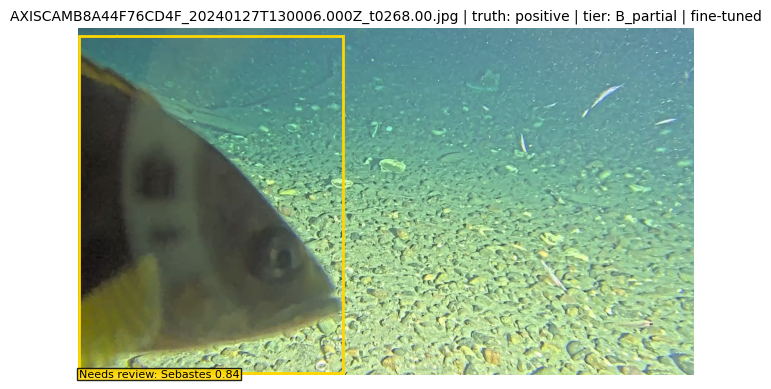

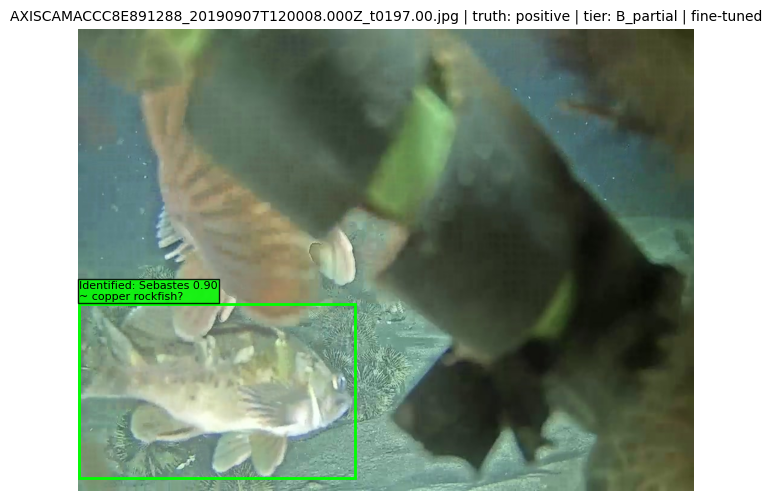

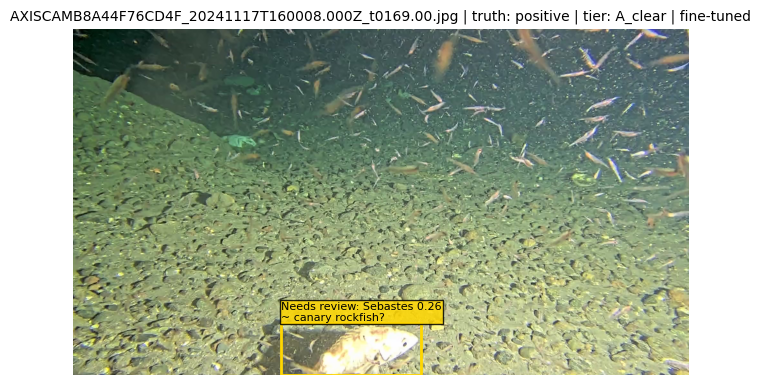

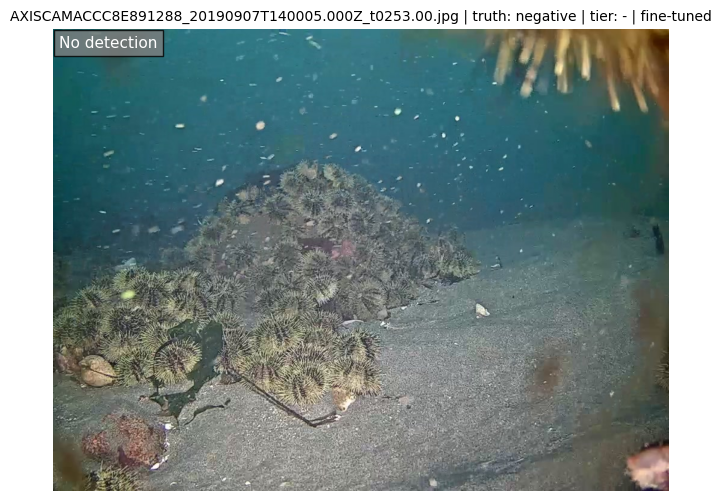

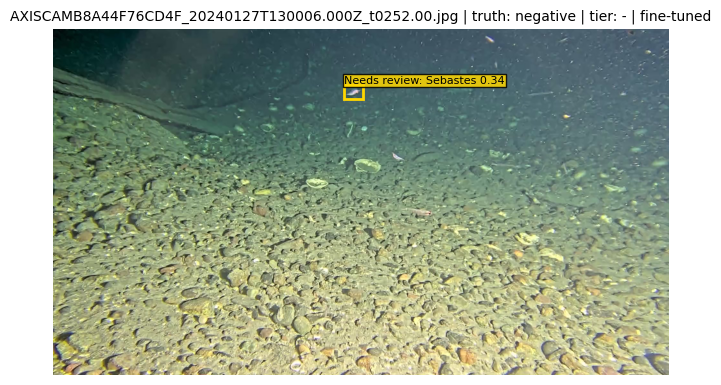

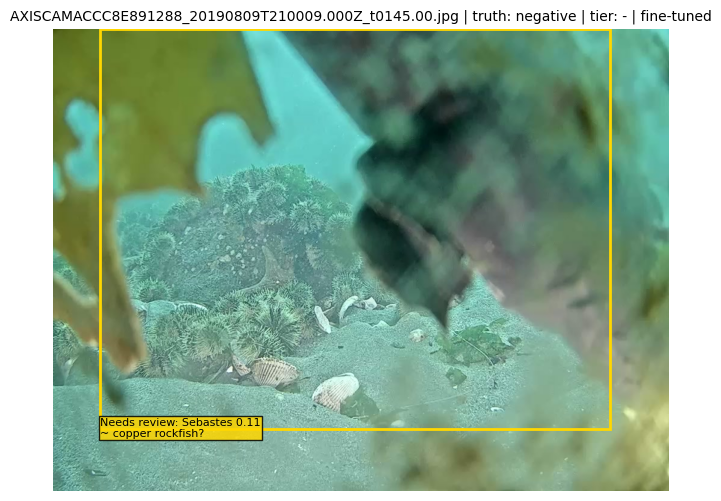

,image,truth,status,score,clade_rank,clade,species_hint,det_source,det_conf,box,seconds
0,76CD4F_20240127T130006.000Z_t0268.00.jpg,positive,Needs review,0.838,genus,Sebastes,None,cfd,0.90,"[2, 24, 827, 1072]",0.33
1,891288_20190907T120008.000Z_t0197.00.jpg,positive,Identified,0.898,genus,Sebastes,"copper rockfish (0.96, unvalidated)",cfd,0.45,"[1, 456, 459, 746]",0.25
2,76CD4F_20241117T160008.000Z_t0169.00.jpg,positive,Needs review,0.255,genus,Sebastes,"canary rockfish (0.83, unvalidated)",cfd,0.71,"[650, 916, 1087, 1080]",0.24
3,891288_20190907T140005.000Z_t0253.00.jpg,negative,No detection,NaN,None,None,None,NaN,NaN,None,0.20
4,76CD4F_20240127T130006.000Z_t0252.00.jpg,negative,Needs review,0.341,genus,Sebastes,None,cfd,0.43,"[908, 176, 966, 219]",0.28
5,891288_20190809T210009.000Z_t0145.00.jpg,negative,Needs review,0.113,genus,Sebastes,"copper rockfish (0.76, unvalidated)",cfd,0.52,"[78, 0, 926, 664]",0.26


In [23]:
# Step 7b) Run on images + draw boxes (same style as the baseline)
import matplotlib.patches as patches

STATUS_COLOR = {"Identified": "lime", "Needs review": "gold",
                "Not rockfish": "deepskyblue", "No detection": "gray"}
EXAMPLES_DIR = RUN / "examples"; EXAMPLES_DIR.mkdir(exist_ok=True)

def run_one(src, truth=None, name=None):
    """src: a manifest row (df.iloc[i]), an image file path, or an RGB array."""
    if hasattr(src, "zip_path"):                       # manifest row -> stream from S3
        img = load_frame(src)
        name = name or src.image_file
        truth = src.label if truth is None else truth
    elif isinstance(src, np.ndarray):
        img = src
    else:
        img = np.array(Image.open(src).convert("RGB"))
        name = name or Path(src).name
    t0 = time.time()
    recs = run_image_ft(img)
    if DEVICE.startswith("cuda"):
        torch.cuda.synchronize()
    sec = round(time.time() - t0, 2)
    for r in recs:
        sp = r.get("plausible_species")
        r.update(image=name, truth=truth, seconds=sec,
                 species_hint=f"{sp['common']} ({sp['prob']:.2f}, unvalidated)" if sp else None)
    return img, recs

def box_label(r):
    if r["status"] in ("Identified", "Needs review"):
        s = f"{r['status']}: Sebastes {r['score']:.2f}"
        if r.get("species_hint"):
            s += f"\n~ {r['plausible_species']['common']}?"
        return s
    return f"Not rockfish {r['score']:.2f}"

def show_ft(img, recs, title, save=False):
    fig, ax = plt.subplots(figsize=(8, 8 * img.shape[0] / img.shape[1]))
    ax.imshow(img); ax.set_axis_off(); ax.set_title(title, fontsize=10)
    for r in recs:
        if r.get("box") is None:
            ax.text(10, 30, "No detection", color="white", fontsize=11,
                    bbox=dict(facecolor="gray", alpha=0.8))
            continue
        x1, y1, x2, y2 = r["box"]; c = STATUS_COLOR[r["status"]]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=c, lw=2))
        ty = y1 - 6 if y1 > 40 else y2 + 14              # keep the label inside the image
        ax.text(x1, ty, box_label(r), color="black", fontsize=8,
                bbox=dict(facecolor=c, alpha=0.85, pad=1))
    if save:
        out = EXAMPLES_DIR / f"{Path(title.split(' |')[0]).stem}.png"
        fig.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()

COLS = ["image", "truth", "status", "score", "clade_rank", "clade", "species_hint",
        "det_source", "det_conf", "box", "seconds"]

def run_examples(split="test", n_pos=3, n_neg=3, image_files=None, seed=0, save=False):
    """Show frames from the manifest. Pass image_files=[...] to pick specific frames."""
    if image_files is not None:
        rows = df[df.image_file.isin(image_files)]
    else:
        sub = df[df.split == split]
        rows = pd.concat([sub[sub.label == "positive"].sample(min(n_pos, (sub.label == "positive").sum()), random_state=seed),
                          sub[sub.label == "negative"].sample(min(n_neg, (sub.label == "negative").sum()), random_state=seed)])
    all_recs = []
    for _, row in rows.iterrows():
        img, recs = run_one(row)
        show_ft(img, recs, f"{row.image_file} | truth: {row.label} | tier: {row.tier or '-'} | {BEST}", save=save)
        all_recs += recs
    out = pd.DataFrame(all_recs)
    if len(out):
        out["image"] = out["image"].str.slice(-40)       # shorter names in the table
        display(out[[c for c in COLS if c in out.columns]])
    return out

# examples: 3 positives + 3 negatives from test
ex = run_examples("test", n_pos=3, n_neg=3, save=True)

In [27]:
# Export everything the Hugging Face Space needs into ONE file (+ back it up to S3)
name_of = {id(p): n for n, p in clip_model.named_parameters()}
use_ft = BEST == "fine-tuned"

if use_ft:
    set_weights(FT_W)
    tuned_state = {name_of[id(p)]: p.detach().cpu().clone() for p in tune}
    set_weights(BASE_W)
    head_state = {k: v.detach().cpu().clone() for k, v in head.state_dict().items()}
else:
    tuned_state, head_state = {}, None

export = {
    "method": BEST,
    "bioclip": BIOCLIP_NAME,
    "tuned_state": tuned_state,          # named weights of the fine-tuned ViT blocks
    "head": head_state,                  # fine-tuned rockfish head
    "probe": {"coef": probe.coef_[0].astype(np.float32), "intercept": float(probe.intercept_[0])},
    "thresholds": {"needs_review": T_LOW, "identified": T_HIGH},
    "detector": {"chain": list(DETECTORS), "cfd_imgsz": CFD_IMGSZ, "det_conf": DET_CONF,
                 "max_dets": MAX_DETS, "crop_pad": CROP_PAD, "use_clahe": USE_CLAHE,
                 "min_crop": MIN_CROP, "max_box_frac": globals().get("MAX_BOX_FRAC", 1.0)},
    "species": SEB_SPECIES, "species_min": SPECIES_MIN,
    "text_sp": torch.tensor(TEXT_SP), "logit_scale": LOGIT_SCALE,
}
out = RUN / "rockfish_model.pt"
torch.save(export, out)
print(f"saved {out}  ({out.stat().st_size / 1e6:.0f} MB) | method={BEST} | "
      f"review>={T_LOW:.3f} identified>={T_HIGH:.3f} | tuned tensors={len(tuned_state)}")

# sanity check: reload the file and confirm it gives the same score on one crop
chk = torch.load(out, weights_only=False)
x = torch.stack([clip_pre(Image.open(crops_df.crop_path[0]).convert("RGB"))]).to(DEVICE)

def score_now():
    with torch.no_grad(), autocast():
        f = F.normalize(clip_model.encode_image(x).float(), dim=-1)
        if use_ft:
            return torch.sigmoid(head(f).float()).item()
        return float(probe.predict_proba(f.cpu().numpy())[0, 1])

if use_ft:
    set_weights(FT_W); a = score_now()
    set_weights(BASE_W)
    clip_model.load_state_dict({k: v.to(DEVICE) for k, v in chk["tuned_state"].items()}, strict=False)
    b = score_now()
    set_weights(BASE_W)
else:
    a = b = score_now()
print(f"score before save {a:.4f} | after reload {b:.4f} -> {'OK' if abs(a - b) < 1e-3 else 'MISMATCH'}")

# back up to the team S3 folder (the hub stops when idle; the bucket is deleted after the event)
fs.put(str(out), f"{TEAM_DIR}/vic02_finetune_run/rockfish_model.pt")
print("backed up to", f"s3://{TEAM_DIR}/vic02_finetune_run/rockfish_model.pt")

saved vic02_work/finetune_run/rockfish_model.pt  (163 MB) | method=fine-tuned | review>=0.112 identified>=0.884 | tuned tensors=27
score before save 0.1213 | after reload 0.1213 -> OK
backed up to s3://ocean-hackathon-2026/teams/team-critter/vic02_finetune_run/rockfish_model.pt
